# Standalone Colab demo: discrepancy-optimized points on an Earth distribution

This notebook is a **single-file reproduction** of the paper's 3D optimization idea. It does not import repository files, download assets, or require mounted Google Drive data. The spherical geometry, Earth target, discrepancy loss, training loop, plots, and optional animation are all contained below.

Saved outputs include a complete default run: training logs, the loss curve, initial/final point sets, and a static final-frame preview. HTML animation rendering is optional. You can inspect the figures without running any cells. To refresh the outputs, run all cells and save the notebook with its outputs.

Run **Runtime → Run all** in Google Colab. A GPU is used automatically when available, while the default experiment also works on CPU. A successful run should show a lower discrepancy estimate and a final point set that follows the Earth target more closely than the initial Sobol set.

### Optimization pipeline

The notebook is deliberately organized in the same order as one optimization iteration:

1. **Parameterize the point set.** Initialize trainable 2D latent coordinates and map them continuously onto the sphere.
2. **Define the target.** Interpret the embedded Earth map as a normalized probability density over solid angle.
3. **Draw test regions.** Sample random spherical caps and estimate how much target probability each cap should contain.
4. **Measure the current point set.** Count the fraction of optimized points inside every cap and compare it with the target mass.
5. **Backpropagate.** Differentiate the complete discrepancy loss with one `loss.backward()` call.
6. **Update and repeat.** Apply Adam, increase the surrogate boundary sharpness, resample caps, and record snapshots.

The numbered sections and the comments inside `optimize()` follow these six steps.

## 1. Environment and reproducibility

Google Colab already provides NumPy, PyTorch, Matplotlib, and IPython, so no package installation is normally needed.

In [1]:
import base64
import io
import json
import math
import time
import zlib
from dataclasses import asdict, dataclass
from pathlib import Path

from IPython.display import HTML, display
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import animation
import numpy as np
import torch

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DTYPE = torch.float32
print('NumPy:', np.__version__)
print('PyTorch:', torch.__version__)
print('Matplotlib:', matplotlib.__version__)
print('Device:', DEVICE)

NumPy: 2.2.6
PyTorch: 2.9.0+cu130
Matplotlib: 3.10.6
Device: cuda


## 2. Optimization step 1 — parameterize the trainable point set

We optimize unconstrained 2D latents. Mirror-repeat wrapping maps them into the unit square, followed by the same differentiable octahedral square-to-sphere mapping used in the research implementation.

`latent_to_direction` is the only mapping used by the optimizer: each row of `latents` represents one output direction. The initial latent values come from a scrambled Sobol sequence, while Adam is allowed to move them outside `[0, 1]`; mirror-repeat wrapping keeps the resulting spherical mapping continuous.

This section also defines the random spherical caps used as test regions. `HardIndicator` returns exact 0/1 cap membership in the forward pass, so the reported discrepancy is measured on the actual discrete point set. Its backward pass substitutes a sigmoid boundary derivative, providing a useful gradient for points close to a cap boundary.

In [2]:
"""Minimal spherical geometry used by the 3D discrepancy optimizer."""

from __future__ import annotations

import math

import torch


def _gradient_abs(value: torch.Tensor) -> torch.Tensor:
    """Absolute value with a non-zero one-sided derivative at zero."""
    return torch.where(value < 0, -value, value)


def _gradient_sign(value: torch.Tensor) -> torch.Tensor:
    return torch.where(value < 0, -torch.ones_like(value), torch.ones_like(value))


def _soft_sqrt_01(value: torch.Tensor) -> torch.Tensor:
    epsilon = torch.as_tensor(1e-6, dtype=value.dtype, device=value.device)
    return torch.sqrt((value + epsilon) / (1.0 + epsilon))


def mirror_repeat_warping(latents: torch.Tensor) -> torch.Tensor:
    """Mirror arbitrary 2D coordinates back into the unit square."""
    floor_latents = torch.floor(latents)
    mirror_times = torch.abs(floor_latents).sum(dim=-1).to(torch.long)
    odd = (mirror_times % 2) == 1
    return torch.where(
        odd.unsqueeze(-1),
        1.0 - (latents - floor_latents),
        latents - floor_latents,
    )


def octahedral_square_to_sphere(latents: torch.Tensor) -> torch.Tensor:
    """Differentiable equal-area-style octahedral square-to-sphere mapping."""
    uv = latents * 2.0 - 1.0
    abs_uv = _gradient_abs(uv)
    diagonal = 1.0 - abs_uv.sum(dim=-1)
    radius = 1.0 - _gradient_abs(diagonal)
    radius_squared = radius.square()

    z = torch.where(diagonal < 0, radius_squared - 1.0, 1.0 - radius_squared)
    phi_prime = torch.zeros_like(radius)
    valid = radius > 1e-6
    phi_prime[valid] = 0.25 * math.pi * (
        (abs_uv[valid, 1] - abs_uv[valid, 0]) / radius[valid] + 1.0
    )

    sin_phi = _gradient_sign(uv[:, 1]) * torch.sin(phi_prime)
    cos_phi = _gradient_sign(uv[:, 0]) * torch.cos(phi_prime)
    sin_theta = radius * _soft_sqrt_01(2.0 - radius_squared)
    directions = torch.stack((cos_phi * sin_theta, sin_phi * sin_theta, z), dim=-1)
    return torch.nn.functional.normalize(directions, dim=-1)


def latent_to_direction(latents: torch.Tensor) -> torch.Tensor:
    return octahedral_square_to_sphere(mirror_repeat_warping(latents))


def uniform_sample_sphere(random_values: torch.Tensor) -> torch.Tensor:
    if random_values.shape[-1] != 2:
        raise ValueError("Sphere sampling requires random values with shape [..., 2].")
    z = 1.0 - 2.0 * random_values[..., 0]
    radius = torch.sqrt(torch.clamp_min(1.0 - z.square(), 0.0))
    phi = 2.0 * math.pi * random_values[..., 1]
    return torch.stack((radius * torch.cos(phi), radius * torch.sin(phi), z), dim=-1)


def uniform_sample_hemisphere(random_values: torch.Tensor) -> torch.Tensor:
    if random_values.shape[-1] != 2:
        raise ValueError("Hemisphere sampling requires random values with shape [..., 2].")
    z = random_values[..., 0]
    radius = torch.sqrt(torch.clamp_min(1.0 - z.square(), 0.0))
    phi = 2.0 * math.pi * random_values[..., 1]
    return torch.stack((radius * torch.cos(phi), radius * torch.sin(phi), z), dim=-1)


def sample_spherical_caps(
    count: int,
    *,
    device: torch.device,
    dtype: torch.dtype,
    generator: torch.Generator,
) -> torch.Tensor:
    """Return caps as [center_x, center_y, center_z, angular_radius]."""
    center_random = torch.rand((count, 2), device=device, dtype=dtype, generator=generator)
    centers = uniform_sample_sphere(center_random)
    angular_radius = torch.rand((count, 1), device=device, dtype=dtype, generator=generator)
    angular_radius = torch.clamp_min(angular_radius * math.pi, 1e-8)
    return torch.cat((centers, angular_radius), dim=-1)


def uniform_cap_probability(caps: torch.Tensor) -> torch.Tensor:
    """Normalized spherical-cap area under the uniform sphere distribution."""
    return torch.sin(0.5 * caps[:, 3]).square()


class _StableAcos(torch.autograd.Function):
    """Exact forward angles; bound only the derivative at parallel directions."""

    @staticmethod
    def forward(ctx, cosine):
        cosine = cosine.clamp(-1.0, 1.0)
        ctx.save_for_backward(cosine)
        return torch.acos(cosine)

    @staticmethod
    def backward(ctx, gradient):
        (cosine,) = ctx.saved_tensors
        return -gradient / torch.sqrt((1.0 - cosine.square()).clamp_min(2e-4))


def point_to_cap_distance(caps: torch.Tensor, points: torch.Tensor) -> torch.Tensor:
    """Signed angular distance [num_points, num_caps], positive inside a cap."""
    dot_value = points @ caps[:, :3].transpose(0, 1)
    radians = _StableAcos.apply(dot_value)
    return caps[:, 3].unsqueeze(0) - radians


def sample_uniform_in_caps(
    caps: torch.Tensor,
    samples_per_cap: int,
    *,
    generator: torch.Generator,
) -> torch.Tensor:
    """Uniformly sample directions inside each cap, returning [R, S, 3]."""
    count = caps.shape[0]
    random_values = torch.rand(
        (count, samples_per_cap, 2),
        dtype=caps.dtype,
        device=caps.device,
        generator=generator,
    )
    z_min = torch.cos(caps[:, 3]).unsqueeze(-1)
    local_z = z_min + (1.0 - z_min) * random_values[..., 0]
    phi = 2.0 * math.pi * random_values[..., 1]
    local_radius = torch.sqrt(torch.clamp_min(1.0 - local_z.square(), 0.0))
    local_x = local_radius * torch.cos(phi)
    local_y = local_radius * torch.sin(phi)

    centers = caps[:, :3]
    helper_z = torch.zeros_like(centers)
    helper_z[:, 2] = 1.0
    helper_x = torch.zeros_like(centers)
    helper_x[:, 0] = 1.0
    near_z = torch.abs(centers[:, 2]) > 0.999
    helper = torch.where(near_z.unsqueeze(-1), helper_x, helper_z)
    tangent_x = torch.nn.functional.normalize(torch.cross(helper, centers, dim=-1), dim=-1)
    tangent_y = torch.cross(centers, tangent_x, dim=-1)

    return (
        local_x.unsqueeze(-1) * tangent_x.unsqueeze(1)
        + local_y.unsqueeze(-1) * tangent_y.unsqueeze(1)
        + local_z.unsqueeze(-1) * centers.unsqueeze(1)
    )


class HardIndicator(torch.autograd.Function):
    """Hard forward with the original scaled STE (deliberately omits tau)."""

    @staticmethod
    def forward(ctx, distance: torch.Tensor, scale: float) -> torch.Tensor:
        ctx.save_for_backward(distance)
        ctx.scale = scale
        return distance.ge(0).to(distance.dtype)

    @staticmethod
    def backward(ctx, grad_output: torch.Tensor):
        (distance,) = ctx.saved_tensors
        sigmoid = torch.sigmoid(distance * ctx.scale)
        surrogate = sigmoid * (1.0 - sigmoid)
        return surrogate * grad_output, None


hard_indicator = HardIndicator.apply


def cap_indicator(caps: torch.Tensor, points: torch.Tensor, tau: float) -> torch.Tensor:
    """Exact dot-product membership, with a bounded angular surrogate backward."""
    cosine = points @ caps[:, :3].T
    inside = (cosine >= torch.cos(caps[:, 3])[None]).to(points.dtype)
    distance = caps[:, 3][None] - _StableAcos.apply(cosine)
    surrogate = hard_indicator(distance, tau)
    return surrogate + (inside - surrogate).detach()


_sample_spherical_caps = sample_spherical_caps
def sample_spherical_caps(count, generator):
    return _sample_spherical_caps(count, device=DEVICE, dtype=DTYPE, generator=generator)


## 3. Optimization step 2 — construct the target distribution

A compact 256×128 binary Earth mask is embedded in this notebook as compressed bits. The target is interpreted as an equirectangular environment map. Multiplication by `sin(theta)` converts image-space luminance weights into a correctly normalized solid-angle PDF before building the marginal and conditional CDFs.

`EnvironmentMap.sample()` draws directions from that distribution for Monte Carlo estimates. `EnvironmentMap.pdf()` evaluates the corresponding density per steradian. Together these two operations are the target-side interface used by the optimizer; replacing the Earth map does not change the point-set optimization code.

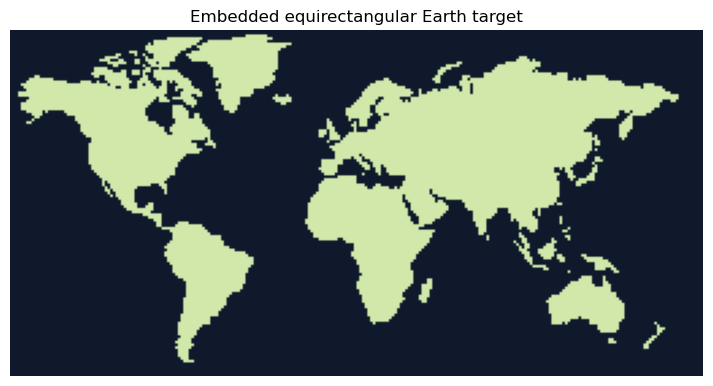

In [3]:
# Step 2a: decode the embedded target. No file or network access is needed.
EARTH_MASK_B64 = (
    'eNrV171vHEUUAPCZjLklivFaosCIwEYUpMSIJlEsNl1K/gTSpXVEgYuIHYfiGqSkoqFwOkpSpruxjJQGyXSUHmQJl9nDkdgT633MzryZebPeOwpo2OY+frezs2/ee7PH2H918G4Flh0rQS7lDNoKVpz/DizAHMuHhzPD7Qr/xni9jDeKrjCul93Z43tmesu9YDebMvUN6ntHZTMYv7hLPD99X7Mq+oTxZK6Cfa7NLQR/xHLqvGafmBGDc20+KOLtg6/a3vE7Ic1gz8jwcHav6136y3Ez2R3U+4wf6AdAzp/wwz7YmZ0CN4tS1KegMvRttsFnvf/QuMGbnSeL+ledu/F5wyYC3NH/3nwNf85fHOlrbnkzkwXixLne6TMDoHt48bIWbnlzc9ZtdJhJhmP91Obu8gXM37rwbr4q3JvDLnNewqKE4LX3/d8zkB9an0M8OhsKgIvjOmtYZbwq88Td9Re6EQ0rjXfVj8S/ZTleZ8/4el8kQA+GrvNNbsMpFqOucuk8T9xERLzOrSuzUEP/vl+BOrP+M6Zaexx9qu362uujZ00Vfb3/RlrPXHGure1GZ9dtsvSZ26JP+C6JzY4vPuhyV7sT8ZBM/lFwOHDJl3EevEndrt4dHqNvYoq1ZD4co0/p2uziPYdkY5+Su+/krs///rAFKU5I+OQN4tqGd60k56vQvPrZuoKEpb4ZL+XnR9194tQldext6eITxx/DjMSPOr6PpQENnR9OptAvY3w18db7l8H3Y/+ILu+ECTBJHCdTyncPkL/j3nn0QnLv0+Ases5uPEE/FaGBkdZZuXQxx9GUdH/fuvo0RD8sg38cwleAHc0u+F7wmzBXfqTfpPf7cXfqWPDzP3B+pNm/17K7MZXh1dCvBq9G/Y2WRAJm50NnLYkkzFwJkw3AF5Lzg7/40L/eIpl+DLJ/eU78s1uJK5q9NmwN8Vegqhp+Sbb3mvgZyKKGp8kOWhE/NXuNrp4Odtjoc7NXqUptJhcgmT5vzM+/0IkLoYIvapNG+cBd/3LlKa2nW7wrIIGVmrGr+ko6Qbe5YeGZ6aj1xHF3wsY1YW8OHiFyV0HoTK6b34x4eeBWXk7Y48H1u9Dr+ql/xNTgASg2mF7eFunDWIUlwLGVXMvk4HyXcBxbyUahhuf7CNrXrLg0vo+gvRGRP98ajG/nxb1PbyVL4J1hK+ByK2uS+w/uck3GqvBxkW4itS+JbuCMugn/+bjjZa8wLukDLAa4hGbsEdHHJZ7PPthMEyz4NhbdZhrADn+Hzrut1Fv0usYrXh93XftH7tQbfFWaZlx0ha9S+4inLvH+97VvVZcLqPdDRRPtskvlS02NeAGxldEECTvYMse7ybsl3qx0HryNrThx5R+gvJ+Mu39w7wS9v/AhtJXXAmTsMWLkz1ElefR21MMVxEhWliSDxWjWcvofY+SIPUroMY09MBvxjMUMFqPjb688n7pQq/+c/lvn/+CsZv/P42+QZ788'
)
packed = zlib.decompress(base64.b64decode(EARTH_MASK_B64))
earth_mask = np.unpackbits(np.frombuffer(packed, dtype=np.uint8))[:128 * 256]
earth_mask = earth_mask.reshape(128, 256).astype(np.float32)
ocean_color = np.array([0.06, 0.10, 0.17], dtype=np.float32)
land_color = np.array([0.82, 0.91, 0.67], dtype=np.float32)
earth_texture = ocean_color * (1.0 - earth_mask[..., None]) + land_color * earth_mask[..., None]

# Step 2b: exact per-texel solid-angle sampling and luminance PDF.
class EnvironmentMap:
    """Piecewise-constant spherical distribution built from a NumPy envmap."""

    def __init__(
        self,
        path: str | Path | np.ndarray,
        *,
        device: torch.device,
        dtype: torch.dtype = torch.float32,
    ) -> None:
        if isinstance(path, np.ndarray):
            image = path
        else:
            path = Path(path)
            if path.suffix.lower() == ".npy":
                image = np.load(path)
            elif path.suffix.lower() in (".png", ".jpg", ".jpeg"):
                import matplotlib.image as mpimg
                image = mpimg.imread(path)
            else:
                raise ValueError("Environment maps must be .npy, .png, .jpg, or .jpeg files.")
        image = np.array(image, copy=True)
        if image.ndim == 2:
            image = np.repeat(image[..., None], 3, axis=-1)
        elif image.ndim == 3 and image.shape[-1] == 4:
            image = image[..., :3]
        if image.ndim != 3 or image.shape[-1] != 3:
            raise ValueError(f"Expected envmap shape [H,W], [H,W,3], or [H,W,4], got {image.shape}.")
        if not np.isfinite(image).all():
            raise ValueError(f"Environment map contains NaN or Inf: {path}")

        self.path = path if isinstance(path, Path) else None
        self.device = device
        self.dtype = dtype
        self.image = torch.as_tensor(image, device=device, dtype=dtype)
        self.height, self.width, _ = self.image.shape
        if self.height == 0 or self.width == 0:
            raise ValueError("Environment map dimensions must be nonzero.")

        luminance = (
            0.212671 * self.image[..., 0]
            + 0.715160 * self.image[..., 1]
            + 0.072169 * self.image[..., 2]
        )
        self.luminance = torch.clamp_min(luminance, 0.0)
        # Double precision avoids cancellation near the poles and in the CDF.
        theta_edges = torch.arange(self.height + 1, device=device, dtype=torch.float64)
        theta_edges = theta_edges * (math.pi / self.height)
        self.cos_theta_edges = torch.cos(theta_edges)
        self.texel_solid_angle = (2.0 * math.pi / self.width) * (
            self.cos_theta_edges[:-1] - self.cos_theta_edges[1:]
        )
        weights = self.luminance.double() * self.texel_solid_angle[:, None]
        total_weight = weights.sum()
        if not torch.isfinite(total_weight) or total_weight <= 0:
            raise ValueError(f"Environment map has no positive luminance: {path}")

        self.texel_probability = weights / total_weight
        self.texel_pdf = (self.luminance.double() / total_weight).to(dtype)
        self.cdf = self.texel_probability.flatten().cumsum(0)
        # Normalize the whole CDF rather than changing only its final element.
        self.cdf = self.cdf / self.cdf[-1]

    def _uv_to_direction(self, u: torch.Tensor, v: torch.Tensor) -> torch.Tensor:
        theta = v * math.pi
        phi = u * (2.0 * math.pi)
        sin_theta = torch.sin(theta)
        return torch.stack(
            (sin_theta * torch.cos(phi), sin_theta * torch.sin(phi), torch.cos(theta)),
            dim=-1,
        )

    def direction_to_uv(self, directions: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        theta = torch.atan2(torch.linalg.vector_norm(directions[..., :2], dim=-1), directions[..., 2])
        phi = torch.remainder(torch.atan2(directions[..., 1], directions[..., 0]), 2.0 * math.pi)
        return phi / (2.0 * math.pi), theta / math.pi

    def pdf(self, directions: torch.Tensor) -> torch.Tensor:
        u, v = self.direction_to_uv(directions)
        column = torch.clamp((u * self.width).to(torch.long), 0, self.width - 1)
        row = torch.clamp((v * self.height).to(torch.long), 0, self.height - 1)
        return self.texel_pdf[row, column]

    def sample(
        self,
        count: int,
        *,
        generator: torch.Generator,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        random_values = torch.rand(
            (count, 3),
            device=self.device,
            dtype=torch.float64,
            generator=generator,
        )
        return self.sample_from_uniform(random_values)

    def sample_from_uniform(self, random_values: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        """Map [N,3] uniforms to texels, then sample phi and cos(theta) there."""
        random_values = random_values.to(device=self.device, dtype=torch.float64)
        if random_values.ndim != 2 or random_values.shape[1] != 3:
            raise ValueError("Environment sampling requires [N,3] uniforms.")
        if not torch.all(torch.isfinite(random_values) & (random_values >= 0) & (random_values <= 1)):
            raise ValueError("Uniform samples must be finite and within [0,1].")
        one = random_values.new_tensor(1.0)
        choice = random_values[:, 0].clamp_max(torch.nextafter(one, one * 0))
        # right=True skips zero-probability CDF plateaus, including a leading zero.
        index = torch.searchsorted(self.cdf, choice.contiguous(), right=True)
        row, column = index // self.width, index % self.width
        # Endpoint uniforms represent measure-zero boundaries. Move only those
        # endpoints to the interior, rather than clipping a finite probability band.
        jitter = random_values[:, 1:]
        jitter = torch.where((jitter == 0) | (jitter == 1), 0.5, jitter)
        phi = (column + jitter[:, 0]) * (2.0 * math.pi / self.width)
        top, bottom = self.cos_theta_edges[row], self.cos_theta_edges[row + 1]
        z = top + (bottom - top) * jitter[:, 1]
        radius = torch.sqrt((1.0 - z.square()).clamp_min(0.0))
        directions = torch.stack((radius * torch.cos(phi), radius * torch.sin(phi), z), -1)
        directions = directions.to(self.dtype)
        # Casting to float32 can round an interior point into a neighboring texel.
        # Correct only those unrepresentable boundary samples to the texel center.
        u, v = self.direction_to_uv(directions)
        actual_row = (v * self.height).long().clamp(0, self.height - 1)
        actual_column = (u * self.width).long().clamp(0, self.width - 1)
        rounded_outside = (actual_row != row) | (actual_column != column)
        center_z = 0.5 * (top + bottom)
        center_radius = torch.sqrt((1.0 - center_z.square()).clamp_min(0))
        center_phi = (column + 0.5) * (2.0 * math.pi / self.width)
        centers = torch.stack((center_radius * torch.cos(center_phi),
                               center_radius * torch.sin(center_phi), center_z), -1).to(self.dtype)
        directions = torch.where(rounded_outside[:, None], centers, directions)
        return directions, self.texel_pdf[row, column]

# This target object is the only distribution-specific input used below.
target = EnvironmentMap(earth_mask, device=DEVICE, dtype=DTYPE)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.imshow(earth_texture, origin='upper')
ax.set_title('Embedded equirectangular Earth target')
ax.axis('off')
plt.show()

## 4. Optimization step 3 — sample caps and estimate their target mass

At every epoch we draw a fresh collection of random spherical caps. For cap $C_j$, the target quantity is $P_{target}(C_j)$: the probability mass that the Earth distribution assigns to that region.

Because the main proposal is the normalized Earth PDF itself, the Monte Carlo estimator is simply the fraction of Earth-importance samples inside each cap. Very small caps may receive too few hits, so they are re-estimated using uniform samples drawn directly inside the cap. This fallback reduces variance without changing the quantity being estimated.
Fallback selection uses independent pilot samples. Pixel density is normalized by exact solid angle; finite-sample cap estimates are not clipped, since clipping would add bias.


In [4]:
@torch.no_grad()
def estimate_cap_masses(caps, sample_count, min_hits, fallback_samples, generator):
    """Estimate Earth probability in every cap, with an independent fallback pilot."""
    if sample_count <= 0:
        raise ValueError("sample_count must be positive.")
    centers = caps[:, :3]
    cosine_radii = torch.cos(caps[:, 3])

    # Earth samples come from the target PDF, so every importance weight is one.
    directions, _ = target.sample(sample_count, generator=generator)
    inside = directions @ centers.T >= cosine_radii[None]
    masses = inside.to(caps.dtype).mean(dim=0)

    if min_hits > 0 and fallback_samples > 0:
        # Select small caps using separate samples to avoid selection bias.
        pilot, _ = target.sample(sample_count, generator=generator)
        pilot_hits = (pilot @ centers.T >= cosine_radii[None]).sum(dim=0)
        indices = torch.nonzero(pilot_hits < min_hits, as_tuple=False).flatten()
        if indices.numel():
            small_caps = caps[indices]
            local_directions = sample_uniform_in_caps(
                small_caps, fallback_samples, generator=generator,
            )
            local_pdf = target.pdf(local_directions.reshape(-1, 3)).reshape(
                len(indices), fallback_samples,
            )
            solid_angles = 4.0 * math.pi * uniform_cap_probability(small_caps)
            masses[indices] = local_pdf.mean(dim=1) * solid_angles
    return masses


## 5. Optimization steps 4-5: discrepancy and backward

For optimized directions $x_i$ and caps $C_j$, the current point-set mass is $\hat P(C_j)=N^{-1}\sum_i 1[x_i \in C_j]$. The loss is the root mean square of $\hat P(C_j)-P_{target}(C_j)$ over the sampled caps.

`discrepancy_loss()` computes the complete `[points, caps]` membership matrix. Each epoch calls `loss.backward()` once, then performs one Adam update. This keeps the demonstration close to the mathematical formulation and avoids extra batching machinery at the default size of 256 points and 1024 caps.

In [5]:
# Experiment size and optimization schedules.
@dataclass(frozen=True)
class Config:
    npoints: int = 256
    epochs: int = 3000
    nregions: int = 1024
    target_samples: int = 2048
    min_cap_hits: int = 16
    fallback_samples: int = 32
    learning_rate: float = 5e-4
    final_learning_rate: float = 5e-7
    tau_start: float = 20.0
    tau_end: float = 1000.0
    snapshot_every: int = 15
    seed: int = 0

# Steps 4-5: compare point-set and target masses using the complete matrix.
def discrepancy_loss(latents, caps, cap_masses, tau):
    directions = latent_to_direction(latents)
    point_masses = cap_indicator(caps, directions, tau).mean(dim=0)
    residual = point_masses - cap_masses
    return torch.sqrt(residual.square().mean() + 1e-12)

def lr_factor(step, total_steps, initial_rate, final_rate, alpha=0.9):
    linear = min(max(step, 0), total_steps) / max(1, total_steps)
    curved = -math.log(1.0 - alpha * linear) / -math.log(1.0 - alpha)
    ratio = final_rate / initial_rate
    return 1.0 - (1.0 - ratio) * curved

# Step 6: assemble steps 1-5 into the complete stochastic optimization loop.
def optimize(config):
    generator = torch.Generator(device=DEVICE).manual_seed(config.seed)
    sobol = torch.quasirandom.SobolEngine(2, scramble=True, seed=config.seed)
    # 1. Initialize the trainable point parameters with broad Sobol coverage.
    latents = sobol.draw(config.npoints).to(device=DEVICE, dtype=DTYPE).requires_grad_(True)
    optimizer = torch.optim.Adam([latents], lr=config.learning_rate)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: lr_factor(
            step, config.epochs, config.learning_rate, config.final_learning_rate
        )
    )
    losses = []
    snapshot_epochs = [0]
    snapshots = [latents.detach().cpu().clone()]
    report_every = max(1, config.epochs // 10)
    for epoch in range(config.epochs):
        # 2. Resample spherical test regions; this approximates the cap integral.
        caps = sample_spherical_caps(config.nregions, generator)
        # 3. Estimate the Earth target's desired probability mass in each cap.
        cap_masses = estimate_cap_masses(
            caps, config.target_samples,
            config.min_cap_hits, config.fallback_samples, generator,
        )
        # Sharpen the surrogate boundary as the point set approaches a solution.
        tau = config.tau_start + (config.tau_end - config.tau_start) * (
            epoch / max(1, config.epochs - 1)
        )
        # 4-5. Evaluate the complete loss and differentiate it once.
        optimizer.zero_grad(set_to_none=True)
        loss = discrepancy_loss(latents, caps, cap_masses, tau)
        loss.backward()
        if not torch.isfinite(loss) or latents.grad is None or not torch.isfinite(latents.grad).all():
            raise FloatingPointError(f'Non-finite optimization state at epoch {epoch + 1}')
        # 6. Move the latent points, then decay the learning rate.
        optimizer.step(); scheduler.step()
        losses.append(float(loss.detach().cpu()))
        completed = epoch + 1
        # Snapshots are visualization-only and never feed back into training.
        if completed % config.snapshot_every == 0 or completed == config.epochs:
            snapshot_epochs.append(completed)
            snapshots.append(latents.detach().cpu().clone())
        if epoch % report_every == 0 or completed == config.epochs:
            print(f'epoch {completed:4d}/{config.epochs}: loss={losses[-1]:.8f}')
    with torch.no_grad():
        final_latents = latents.detach().cpu()
        final_directions = latent_to_direction(latents).detach().cpu()
    return final_latents, final_directions, losses, snapshot_epochs, torch.stack(snapshots)

## 6. Optimization step 6: update the points and repeat

`optimize()` assembles the pieces in iteration order. Each epoch resamples caps, estimates their target masses, evaluates the current point-set discrepancy, calls `loss.backward()`, and performs one Adam update. The hard-indicator surrogate becomes sharper over time through the `tau` schedule.

The default uses 256 points, 3000 epochs, and 1024 spherical caps per epoch. A GPU is recommended. Adjust `npoints`, `epochs`, `nregions`, and `target_samples` to change the experiment size. All point/cap and target-sample/cap matrices are evaluated directly.

In [6]:
config = Config()
start_time = time.perf_counter()
final_latents, final_directions, losses, snapshot_epochs, latent_snapshots = optimize(config)
elapsed = time.perf_counter() - start_time
print(f'Finished in {elapsed:.2f} seconds on {DEVICE}.')
print(f'First reported loss: {losses[0]:.8f}')
print(f'Final loss:          {losses[-1]:.8f}')
print(f'Recorded snapshots: {len(snapshot_epochs)}')

epoch    1/3000: loss=0.09813552
epoch  301/3000: loss=0.03201734
epoch  601/3000: loss=0.01746210
epoch  901/3000: loss=0.01274888
epoch 1201/3000: loss=0.01254533
epoch 1501/3000: loss=0.01704601
epoch 1801/3000: loss=0.01077532
epoch 2101/3000: loss=0.01097723
epoch 2401/3000: loss=0.00941014
epoch 2701/3000: loss=0.01027216
epoch 3000/3000: loss=0.00755023
Finished in 32.87 seconds on cuda.
First reported loss: 0.09813552
Final loss:          0.00755023
Recorded snapshots: 201


## 7. Inspect the result

The loss is stochastic because new caps and target samples are drawn each epoch, so the translucent raw curve is paired with a moving average. In the map views, the initial Sobol directions cover the sphere nearly uniformly; optimization moves the final points toward the target's land mass while preserving broad coverage.

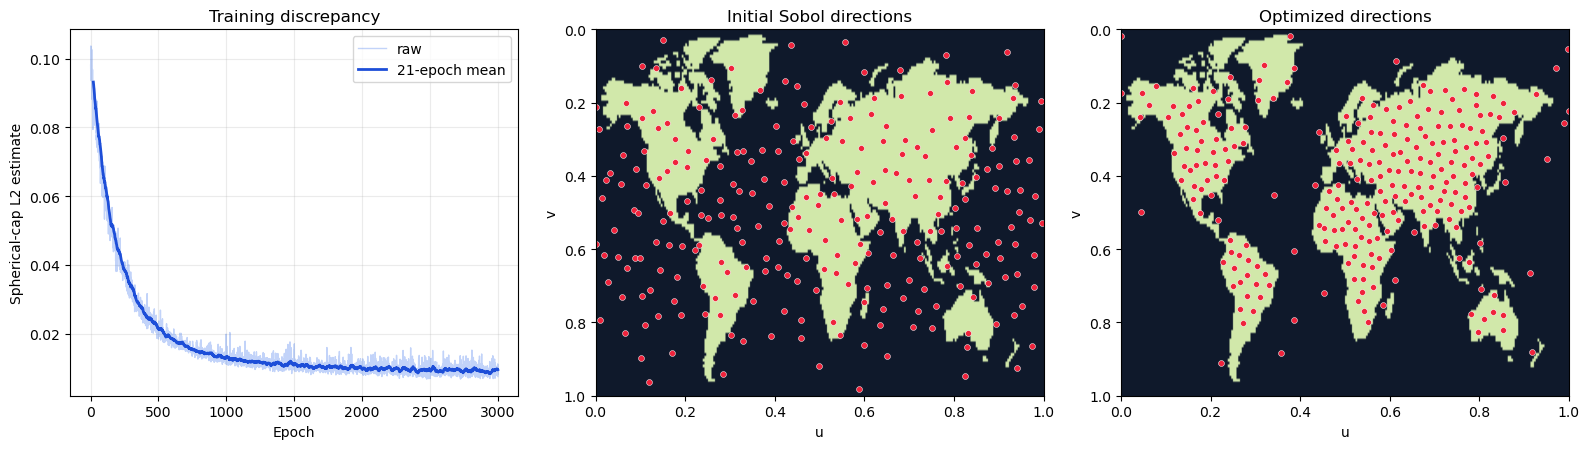

In [7]:
with torch.no_grad():
    initial_directions = latent_to_direction(latent_snapshots[0]).numpy()
final_directions_np = final_directions.numpy()

def directions_to_uv(directions):
    theta = np.arccos(np.clip(directions[:, 2], -1.0, 1.0))
    phi = np.mod(np.arctan2(directions[:, 1], directions[:, 0]), 2.0 * np.pi)
    return phi / (2.0 * np.pi), theta / np.pi

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
epochs = np.arange(1, len(losses) + 1)
axes[0].plot(epochs, losses, color='#2563eb', alpha=0.28, linewidth=1.0, label='raw')
window = min(21, max(3, len(losses) // 12))
smoothed = np.convolve(losses, np.ones(window) / window, mode='valid')
axes[0].plot(epochs[window - 1:], smoothed, color='#1d4ed8', linewidth=2.0, label=f'{window}-epoch mean')
axes[0].set(title='Training discrepancy', xlabel='Epoch', ylabel='Spherical-cap L2 estimate')
axes[0].grid(alpha=0.25); axes[0].legend()

for ax, directions, title in [
    (axes[1], initial_directions, 'Initial Sobol directions'),
    (axes[2], final_directions_np, 'Optimized directions'),
]:
    u, v = directions_to_uv(directions)
    ax.imshow(earth_texture, extent=(0, 1, 1, 0), aspect='auto')
    ax.scatter(u, v, s=18, c='#ef233c', edgecolors='white', linewidths=0.35)
    ax.set(xlim=(0, 1), ylim=(1, 0), title=title, xlabel='u', ylabel='v')
fig.tight_layout()
plt.show()

## 8. Fast-forward training animation

The camera orbits the textured sphere while later optimization snapshots are selected at an accelerated rate. A static final frame is displayed first so the result remains visible in viewers that do not execute JavaScript. The animation is rendered inline as JavaScript/HTML, so FFmpeg is not required.

The saved animation previews the bundled training run. `RENDER_ANIMATION = False` skips regenerating the animation; set it to `True` to update it.

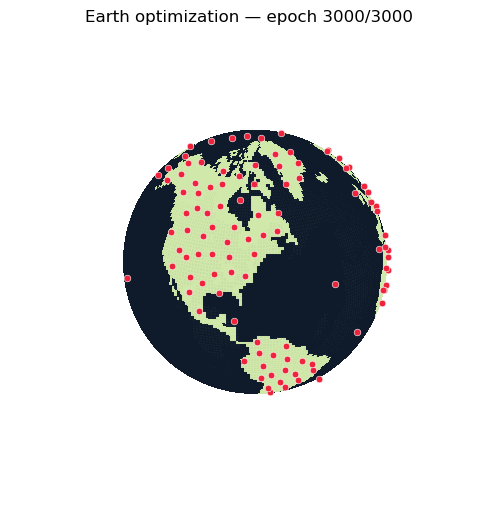

In [8]:
RENDER_ANIMATION = False  # False: do not update the animation; True: regenerate it.
FPS = 10
FAST_FORWARD = 1.8
ROTATION_DEG_PER_FRAME = 7.0

theta = np.linspace(0.0, np.pi, earth_texture.shape[0])
phi = np.linspace(0.0, 2.0 * np.pi, earth_texture.shape[1])
theta_grid, phi_grid = np.meshgrid(theta, phi, indexing='ij')
sphere_xyz = (
    np.sin(theta_grid) * np.cos(phi_grid),
    np.sin(theta_grid) * np.sin(phi_grid),
    np.cos(theta_grid),
)
with torch.no_grad():
    snapshot_directions = [latent_to_direction(snapshot).numpy() for snapshot in latent_snapshots]
output_frame_count = max(2, int(math.ceil(len(snapshot_directions) / FAST_FORWARD)))
source_indices = np.rint(
    np.linspace(0, len(snapshot_directions) - 1, output_frame_count)
).astype(int)

figure = plt.figure(figsize=(6.2, 6.2))
# update_frame filters out back-facing points; draw the visible points over the surface.
axis = figure.add_subplot(111, projection='3d', computed_zorder=False)
axis.plot_surface(
    *sphere_xyz, facecolors=earth_texture, rstride=1, cstride=1,
    linewidth=0, antialiased=False, shade=False, alpha=0.96,
)
axis.set(xlim=(-1.08, 1.08), ylim=(-1.08, 1.08), zlim=(-1.08, 1.08))
axis.set_box_aspect((1, 1, 1)); axis.set_axis_off()
points_artist = axis.scatter([], [], [], s=23, c='#ef233c', edgecolors='white', linewidths=0.4, zorder=3, depthshade=False)
title_artist = axis.set_title('')

def update_frame(frame_index):
    source_index = int(source_indices[frame_index])
    azimuth = 30.0 + frame_index * ROTATION_DEG_PER_FRAME
    elevation = 22.0
    azimuth_rad, elevation_rad = np.deg2rad([azimuth, elevation])
    camera = np.array([
        np.cos(elevation_rad) * np.cos(azimuth_rad),
        np.cos(elevation_rad) * np.sin(azimuth_rad),
        np.sin(elevation_rad),
    ])
    directions = snapshot_directions[source_index]
    visible = directions[directions @ camera > 0.0] * 1.012
    points_artist._offsets3d = (visible[:, 0], visible[:, 1], visible[:, 2])
    title_artist.set_text(
        f'Earth optimization — epoch {snapshot_epochs[source_index]}/{config.epochs}'
    )
    axis.view_init(elev=elevation, azim=azimuth)
    return points_artist, title_artist

def make_fast_forward_animation():
    return animation.FuncAnimation(
        figure, update_frame, frames=output_frame_count, interval=1000 / FPS, blit=False
    )

fast_forward_animation = None
update_frame(output_frame_count - 1)
display(figure)
plt.close(figure)
if RENDER_ANIMATION:
    fast_forward_animation = make_fast_forward_animation()
    display(HTML(fast_forward_animation.to_jshtml(fps=FPS, default_mode='once')))

## 9. Save and optionally download the result

The NPZ records the optimized latents, directions, loss history, snapshots, snapshot epochs, and configuration. In Colab, set `DOWNLOAD_RESULT = True` to open the browser download prompt. GIF export is optional because the inline animation above needs no external encoder.

In [9]:
RESULT_PATH = Path('earth_discrepancy_demo.npz')
np.savez_compressed(
    RESULT_PATH,
    latents=final_latents.numpy(),
    directions=final_directions_np,
    losses=np.asarray(losses, dtype=np.float32),
    snapshot_epochs=np.asarray(snapshot_epochs, dtype=np.int64),
    latent_snapshots=latent_snapshots.numpy(),
    config_json=np.asarray(json.dumps(asdict(config), indent=2)),
)
print('Saved:', RESULT_PATH.resolve())

SAVE_GIF = False
if SAVE_GIF:
    if fast_forward_animation is None:
        fast_forward_animation = make_fast_forward_animation()
    gif_path = Path('earth_discrepancy_fast_forward.gif')
    fast_forward_animation.save(gif_path, writer=animation.PillowWriter(fps=FPS), dpi=90)
    print('Saved:', gif_path.resolve())

DOWNLOAD_RESULT = False
if DOWNLOAD_RESULT:
    try:
        from google.colab import files
        files.download(str(RESULT_PATH))
    except ImportError:
        print('Automatic download is only available in Google Colab.')

Saved: D:\Programming\dl-rendering\opensource\notebook_outputs\earth_direct_3000\earth_discrepancy_demo.npz


## Conclusion

This run demonstrates the complete algorithmic path without pretrained networks or hidden project files: construct a non-uniform spherical target, estimate spherical-cap masses, optimize a point set through exact hard occupancies with surrogate gradients, and visualize the resulting distribution. The optimizer evaluates the complete discrepancy loss and uses one backward pass per epoch.